# Phase 3: Exploratory Data Analysis (EDA)

**What:** Look at the data with charts and tables to find patterns in readmissions.

**Why:** I need to understand the data before any modelling. EDA shows problems like class imbalance and features that are strongly linked.

## Setup

**What:** Import the libraries and set the file paths.

**Why:** Keeping them at the top makes them easy to change.

In [3]:
import numpy as np # numbers and np.select
import pandas as pd # tables
import matplotlib.pyplot as plt # charts
import seaborn as sns # nice charts

ENRICHED = '../data/processed/02_enriched.csv'   # Phase 2 output
ID_MAPPING = '../data/raw/IDs_mapping.csv'       # ID names file

sns.set_theme(style='whitegrid') # clean chart style

## Loading the Data and Making the Target

**What:** Load `02_enriched.csv` and make a new column `readmit_30` (1 = readmitted within 30 days, 0 = not).

**Why:** With 0 and 1, the average of `readmit_30` is the readmission rate. I use this rate for every comparison. `keep_default_na=False` keeps `'None'` as a real value.

In [4]:
# Keep text 'None', treat empty cells as NaN
df = pd.read_csv(ENRICHED, keep_default_na=False, na_values=[''], low_memory=False)
print(df.shape)

# Target: 1 if readmitted within 30 days, else 0
df['readmit_30'] = (df['readmitted'] == '<30').astype(int)

(100114, 50)


## Adding Names to the ID Columns

**What:** Add `admission_type` and `admission_source` name columns using `IDs_mapping.csv`.

**Why:** The brief (spec 3.3) asks for names on the ID columns, because numbers like 1 or 7 mean nothing. The discharge names are added later in section 4.4.

In [5]:
def load_mapping(table_name):
    """Read one table (e.g. 'admission_type_id') from IDs_mapping.csv."""
    mapping, in_table = {}, False
    with open(ID_MAPPING, encoding='utf-8-sig') as file:
        for line in file:
            code, _, description = line.strip().partition(',')
            if code == table_name: # header of the table we want
                in_table = True
            elif code.endswith('_id'): # header of another table
                in_table = False
            elif in_table and code.isdigit(): # a row of our table
                mapping[int(code)] = description.strip().strip('"')
    return mapping


# Add readable names for the two ID columns not yet mapped (spec 3.3)
for id_col, name_col in [('admission_type_id', 'admission_type'),
                         ('admission_source_id', 'admission_source')]:
    df[name_col] = df[id_col].map(load_mapping(id_col))

df[['admission_type', 'admission_source']].isna().mean()   # any unmapped IDs?

admission_type      0.0
admission_source    0.0
dtype: float64

## 1. Readmission Outcomes

**What:** Count plot of `readmitted` (NO, >30, <30), with the % of each.

**Why:** Hospitals are penalised for the `<30` group (HRRP). I need to know how small it is, because that changes how I compare results.

readmitted
NO     53.2
>30    35.5
<30    11.3
Name: proportion, dtype: float64


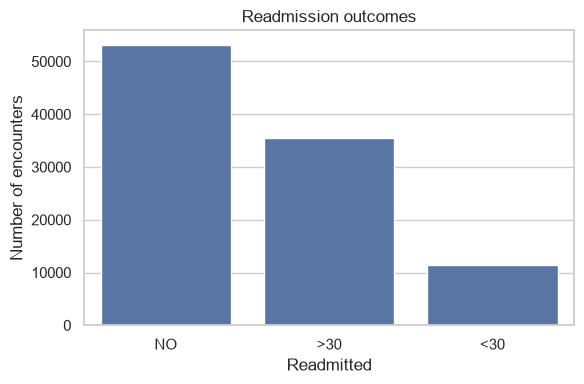

In [6]:
# Perecentage of each outcome
print(df['readmitted'].value_counts(normalize=True).mul(100).round(1))

# Count plot in a fixed order
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='readmitted', order=['NO', '>30', '<30'])
plt.title('Readmission outcomes')
plt.xlabel('Readmitted')
plt.ylabel('Number of encounters')
plt.tight_layout()
plt.show()

**Insight:** The `<30` group is a minority: 11.3%, compared with 53.2% for `NO` and 35.5% for `>30`. This means raw counts and accuracy can mislead (always guessing "not readmitted" would look accurate). So I compare **rates** between groups, and a later model must handle the imbalance.

## 2.1 Age Distribution

**What:** Count plot of age groups, and the share of patients aged 60 or older.

**Why:** To check if diabetes in this data mainly affects older people. This tells me who the results are about.

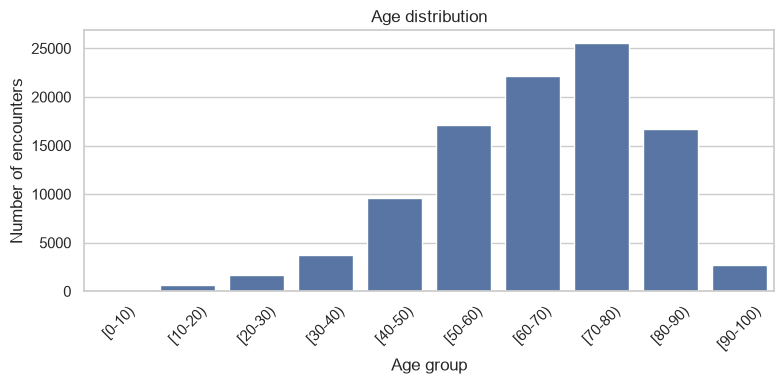

Share aged 60+: 67.0%


In [7]:
# Age groups in order: [0-10) ... [90-100)
age_order = sorted(df['age'].unique())

plt.figure(figsize=(8,4))
sns.countplot(data=df, x='age', order=age_order)
plt.title('Age distribution')
plt.xlabel('Age group')
plt.ylabel('Number of encounters')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Share of patients aged 60 or older
elderly = ['[60-70)', '[70-80)', '[80-90)', '[90-100)']
print(f"Share aged 60+: {df['age'].isin(elderly).mean():.1%}")

**Insight:** About 67% of encounters are patients aged 60 or older, and the biggest age group is 70-80. So diabetes hospital visits here are mostly elderly patients, and the results mainly describe older adults.

## 2.2 Readmission by Race and Gender

**What:** Grouped bar chart of the 30-day readmission rate for each race and gender, with the number of patients.

**Why:** To see if some groups are readmitted more, which could mean unequal care. I print the counts because rates from small groups are not reliable. Missing race rows are skipped, and the few `Unknown/Invalid` gender rows are removed.

              race  gender   mean  count  rate_pct
0  AfricanAmerican  Female  0.113  11531    11.274
1  AfricanAmerican    Male  0.116   7357    11.622
2            Asian  Female  0.076    316     7.595
3            Asian    Male  0.130    316    12.975
4        Caucasian  Female  0.117  39067    11.672
5        Caucasian    Male  0.113  35778    11.269
6         Hispanic  Female  0.092   1090     9.174
7         Hispanic    Male  0.120    934    11.991
8            Other  Female  0.104    738    10.434
9            Other    Male  0.091    747     9.103


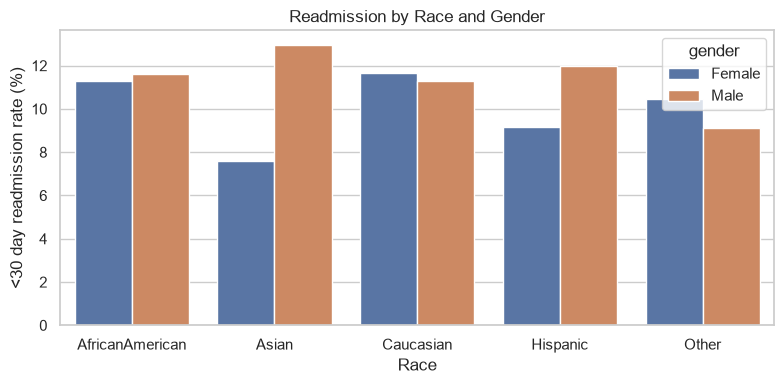

In [10]:
# Keep only Male / Female rows
plot_df = df[df['gender'].isin(['Male', 'Female'])]

# Readmission rate and patient count for each race + gender group
race_gender = (plot_df.groupby(['race', 'gender'])['readmit_30']
               .agg(['mean', 'count']).reset_index())

race_gender['rate_pct'] = race_gender['mean'] * 100
print(race_gender.round(3))

# Grouped bar chart
plt.figure(figsize=(8,4))
sns.barplot(data=race_gender, x='race', y='rate_pct', hue='gender')
plt.title('Readmission by Race and Gender')
plt.xlabel('Race')
plt.ylabel('<30 day readmission rate (%)')
plt.tight_layout()
plt.show()